In [1]:
import csv
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import yaml
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

ROOT = Path.cwd().resolve()
for _ in range(3):
    if (ROOT / "configs" / "base_akf.yaml").is_file():
        break
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from data.crop_dataloader import SRC_H, SRC_W
import importlib
import tracking.efficient.model as efficient_model
importlib.reload(efficient_model)
from tracking.efficient.model import EfficientTracker

GAME, CLIP = "game1", "Clip7"
START, COUNT = "0190.jpg", 50

# "cnn" measures with the crop detector. "dsp" is not wired yet.
DETECTOR = "cnn"
# "search" tiles the frame until the CNN locks. "label" starts from the first visible label.
INIT = "search"

with (ROOT / "configs" / "base_akf.yaml").open() as f:
    cfg = yaml.safe_load(f)
dataset = Path(cfg["paths"]["dataset"])
if not dataset.is_absolute():
    cfg["paths"]["dataset"] = str((ROOT / dataset).resolve())

# Crop size, confidence, measurement clip, and baseline hooks: tracker.rules.
tracker = EfficientTracker()
tracker.rules.use_baseline_to_start = True
tracker.rules.uncertainty_px = 50
tracker.rules.use_baseline_on_miss = True
# False: every frame grows from min_side. True: first crop covers the gate.
tracker.rules.start_at_uncertainty = True
MAX_SIDE = tracker.rules.max_side

VISIBILITY = {0: "not in frame", 1: "visible", 2: "hard to see", 3: "occluded"}
MOVEMENT = {0: "flying", 1: "hit", 2: "bouncing"}


def load_clip(game: str, clip: str) -> list[dict]:
    clip_dir = Path(cfg["paths"]["dataset"]) / game / clip
    frames = []
    with (clip_dir / "Label.csv").open(newline="") as f:
        for row in csv.DictReader(f):
            vis = int(row["visibility"] or 0)
            xy = None
            if vis > 0:
                xy = np.array(
                    [float(row["x-coordinate"]), float(row["y-coordinate"])],
                    dtype=np.float64,
                )
            frames.append(
                {
                    "file": row["file name"],
                    "path": clip_dir / row["file name"],
                    "visibility": vis,
                    "status": int(row["status"] or 0),
                    "xy": xy,
                }
            )
    return frames


def read_gray(path: Path) -> np.ndarray:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(path)
    if gray.shape[1] != SRC_W or gray.shape[0] != SRC_H:
        gray = cv2.resize(gray, (SRC_W, SRC_H), interpolation=cv2.INTER_AREA)
    return gray


def read_rgb(path: Path) -> np.ndarray:
    """Model-resolution RGB, channel-first, for baseline hooks."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    out_w, out_h = tracker.out_w, tracker.out_h
    if bgr.shape[1] != out_w or bgr.shape[0] != out_h:
        bgr = cv2.resize(bgr, (out_w, out_h), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return np.ascontiguousarray(rgb.transpose(2, 0, 1))


def run_clip(frames: list[dict], *, keep: set[int] | None = None) -> list[dict | None]:
    """Positions for one clip. ``keep`` stores CNN heatmaps at those frame indices."""
    if DETECTOR == "dsp":
        raise NotImplementedError(
            "DSP measurement is not wired yet; see notebooks/test_dsp_detector.ipynb"
        )
    if DETECTOR != "cnn":
        raise ValueError(f"unknown detector {DETECTOR!r}")
    if INIT not in ("search", "label"):
        raise ValueError(f"unknown INIT {INIT!r}")

    grays = [read_gray(frame["path"]) for frame in frames]
    rgbs = [read_rgb(frame["path"]) for frame in frames] if tracker.needs_rgbs() else None

    start_xy = None
    start_index = 0
    if INIT == "label":
        for i, frame in enumerate(frames):
            if frame["xy"] is not None:
                start_xy = frame["xy"]
                start_index = i
                break
        else:
            return [None] * len(frames)

    return tracker.find_positions(
        grays,
        rgbs,
        keep_heat=False if keep is None else keep,
        start_xy=start_xy,
        start_index=start_index,
    )


print(
    f"loaded {tracker.cnn_checkpoint.relative_to(ROOT)}  ({tracker.device})  "
    f"detector={DETECTOR}  init={INIT}"
)
print(f"baseline {tracker.baseline_checkpoint.relative_to(ROOT)}  loaded")
print(
    f"hooks  use_baseline_to_start={tracker.rules.use_baseline_to_start}  "
    f"uncertainty_px={tracker.rules.uncertainty_px}  "
    f"use_baseline_on_miss={tracker.rules.use_baseline_on_miss}  "
    f"start_at_uncertainty={tracker.rules.start_at_uncertainty}"
)

clip = load_clip(GAME, CLIP)
start = next(i for i, frame in enumerate(clip) if frame["file"] == START)
window = range(start, start + COUNT)
steps = run_clip(clip, keep=set(window))

print(f"{GAME}/{CLIP}  {clip[start]['file']} → {clip[start + COUNT - 1]['file']}")
for i in window:
    frame, step = clip[i], steps[i]
    if step is None:
        print(f"{frame['file']}  no difference")
        continue
    xy = frame["xy"]
    spread = f"{step['spread']:5.1f}" if np.isfinite(step["spread"]) else "    —"
    r_std = f"{step['r_std']:5.1f}" if np.isfinite(step["r_std"]) else "    —"
    conf = f"{step['conf']:4.2f}" if np.isfinite(step["conf"]) else "   —"
    src = step.get("source") or "—"
    if step["pred"] is None:
        print(f"{frame['file']}  init   spread={spread}  r={r_std}  conf={conf}  source={src}")
        continue
    err = float(np.hypot(*(step["pred"] - xy))) if xy is not None else float("nan")
    err_txt = f"{err:5.1f}" if np.isfinite(err) else "    —"
    choice = "used" if step["z"] is not None else "miss"
    x0, y0, x1, y1 = step["box"]
    crop = f"{step['side']:4d}" if step["side"] else "   —"
    print(
        f"{frame['file']}  {MOVEMENT[frame['status']]:8}  "
        f"{VISIBILITY[frame['visibility']]:12}  "
        f"pred_err={err_txt}  gate={x1 - x0:5.0f}  crop={crop}  "
        f"spread={spread}  r={r_std}  conf={conf}  scale={step['scale']:5.2f}  "
        f"source={src}  {choice}"
    )


loaded models/detection/cnn_detector/saved_models/cnn_detector/cnn_detector.pt  (cuda)  detector=cnn  init=search
baseline models/baseline_cnn/saved_models/baseline_cnn_train1/baseline_cnn_train1.pt  loaded
hooks  use_baseline_to_start=True  uncertainty_px=50  use_baseline_on_miss=True  start_at_uncertainty=True
game1/Clip7  0190.jpg → 0239.jpg
0190.jpg  flying    visible       pred_err=  0.7  gate=   36  crop=  48  spread=  1.9  r=  2.0  conf=0.82  scale= 1.81  source=cnn  used
0191.jpg  flying    hard to see   pred_err=  1.7  gate=   36  crop=  48  spread=  1.6  r=  2.0  conf=0.78  scale= 1.69  source=cnn  used
0192.jpg  flying    visible       pred_err=  2.0  gate=   35  crop=  48  spread=  1.9  r=  2.0  conf=0.80  scale= 1.59  source=cnn  used
0193.jpg  flying    visible       pred_err=  4.0  gate=   34  crop=  48  spread=  1.8  r=  2.0  conf=0.78  scale= 1.50  source=cnn  used
0194.jpg  flying    hard to see   pred_err=  2.0  gate=   34  crop=  48  spread=  1.9  r=  2.0  conf=0.74

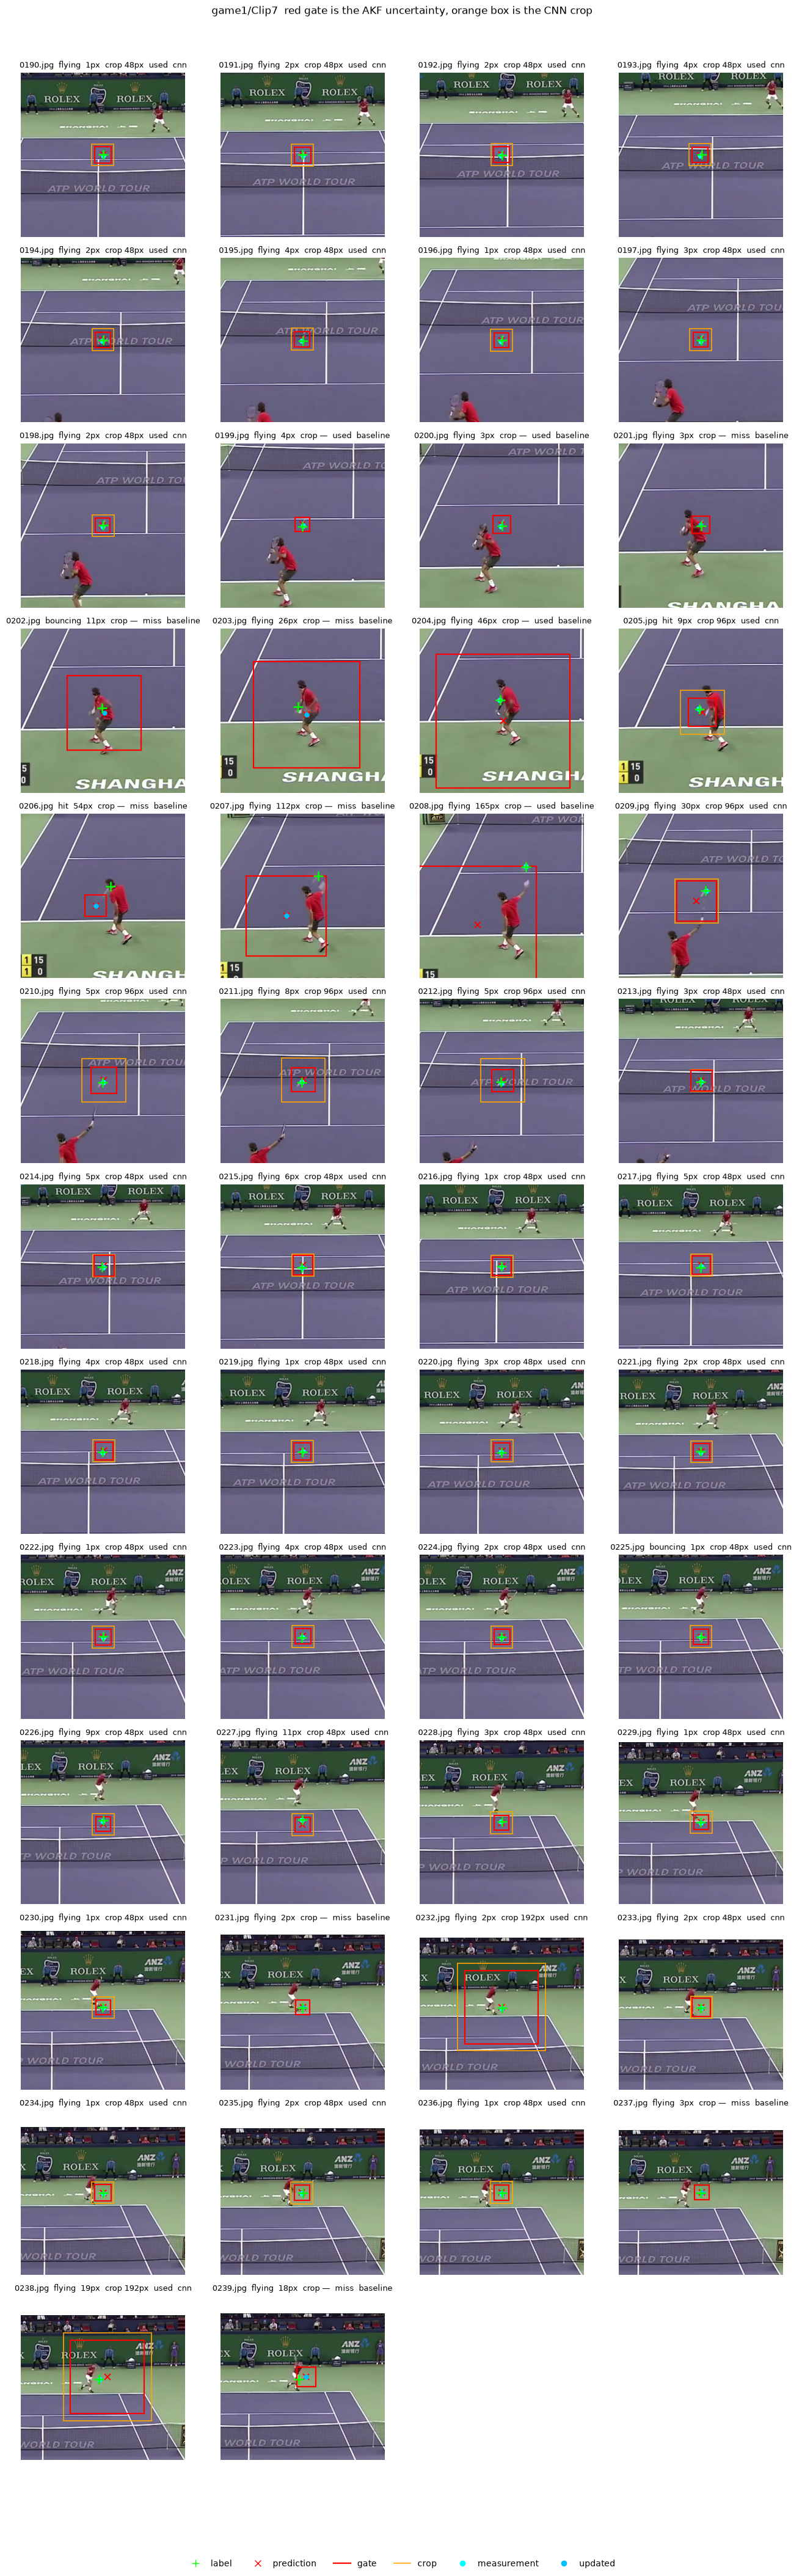

In [2]:
ncols = 4
half = 180
nrows = int(np.ceil(COUNT / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 3.3 * nrows))
for ax, i in zip(np.atleast_1d(axes).ravel(), window):
    frame, step = clip[i], steps[i]
    bgr = cv2.imread(str(frame["path"]), cv2.IMREAD_COLOR)
    ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    if step is None:
        ax.set_title(f"{frame['file']}  no difference", fontsize=9)
        ax.axis("off")
        continue
    heat, origin = step["heat"], step["origin"]
    if heat is not None and origin is not None:
        x0, y0 = origin
        h, w = heat.shape
        rgba = plt.colormaps["magma"](np.clip(heat, 0.0, 1.0))
        rgba[..., 3] = np.clip(heat, 0.0, 1.0)
        ax.imshow(
            rgba,
            extent=(x0 - 0.5, x0 + w - 0.5, y0 + h - 0.5, y0 - 0.5),
        )
    if step["origin"] is not None and step["side"]:
        cx, cy = step["origin"]
        ax.add_patch(
            Rectangle((cx, cy), step["side"], step["side"], fill=False, edgecolor="orange", lw=1.2)
        )
    x0, y0, x1, y1 = step["box"]
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", lw=1.6))
    if step["pred"] is not None:
        ax.plot(*step["pred"], "x", color="red", ms=7, mew=1.4)
    ax.plot(*step["post"], "o", color="deepskyblue", ms=5)
    if step["z"] is not None:
        ax.plot(*step["z"], "o", color="cyan", ms=5)
    xy = frame["xy"]
    if xy is not None:
        ax.plot(*xy, "+", color="lime", ms=11, mew=1.8)
        center = xy if step["pred"] is None else 0.5 * (step["pred"] + xy)
    else:
        center = step["post"]
    ax.set_xlim(center[0] - half, center[0] + half)
    ax.set_ylim(center[1] + half, center[1] - half)
    title = frame["file"]
    if step["pred"] is not None and xy is not None:
        err = float(np.hypot(*(step["pred"] - xy)))
        tag = "used" if step["z"] is not None else "miss"
        crop = f"{step['side']}px" if step["side"] else "—"
        title += f"  {MOVEMENT[frame['status']]}  {err:.0f}px  crop {crop}  {tag}"
    elif step["pred"] is None:
        title += "  init"
    if step.get("source"):
        title += f"  {step['source']}"
    ax.set_title(title, fontsize=9)
    ax.axis("off")

for ax in np.atleast_1d(axes).ravel()[COUNT:]:
    ax.axis("off")

fig.legend(
    handles=[
        Line2D([0], [0], marker="+", color="lime", lw=0, ms=8, label="label"),
        Line2D([0], [0], marker="x", color="red", lw=0, ms=7, label="prediction"),
        Line2D([0], [0], color="red", lw=1.6, label="gate"),
        Line2D([0], [0], color="orange", lw=1.2, label="crop"),
        Line2D([0], [0], marker="o", color="cyan", lw=0, ms=6, label="measurement"),
        Line2D([0], [0], marker="o", color="deepskyblue", lw=0, ms=6, label="updated"),
    ],
    loc="lower center",
    ncol=6,
    frameon=False,
)
fig.suptitle(f"{GAME}/{CLIP}  red gate is the AKF uncertainty, orange box is the CNN crop", fontsize=12)
fig.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.show()


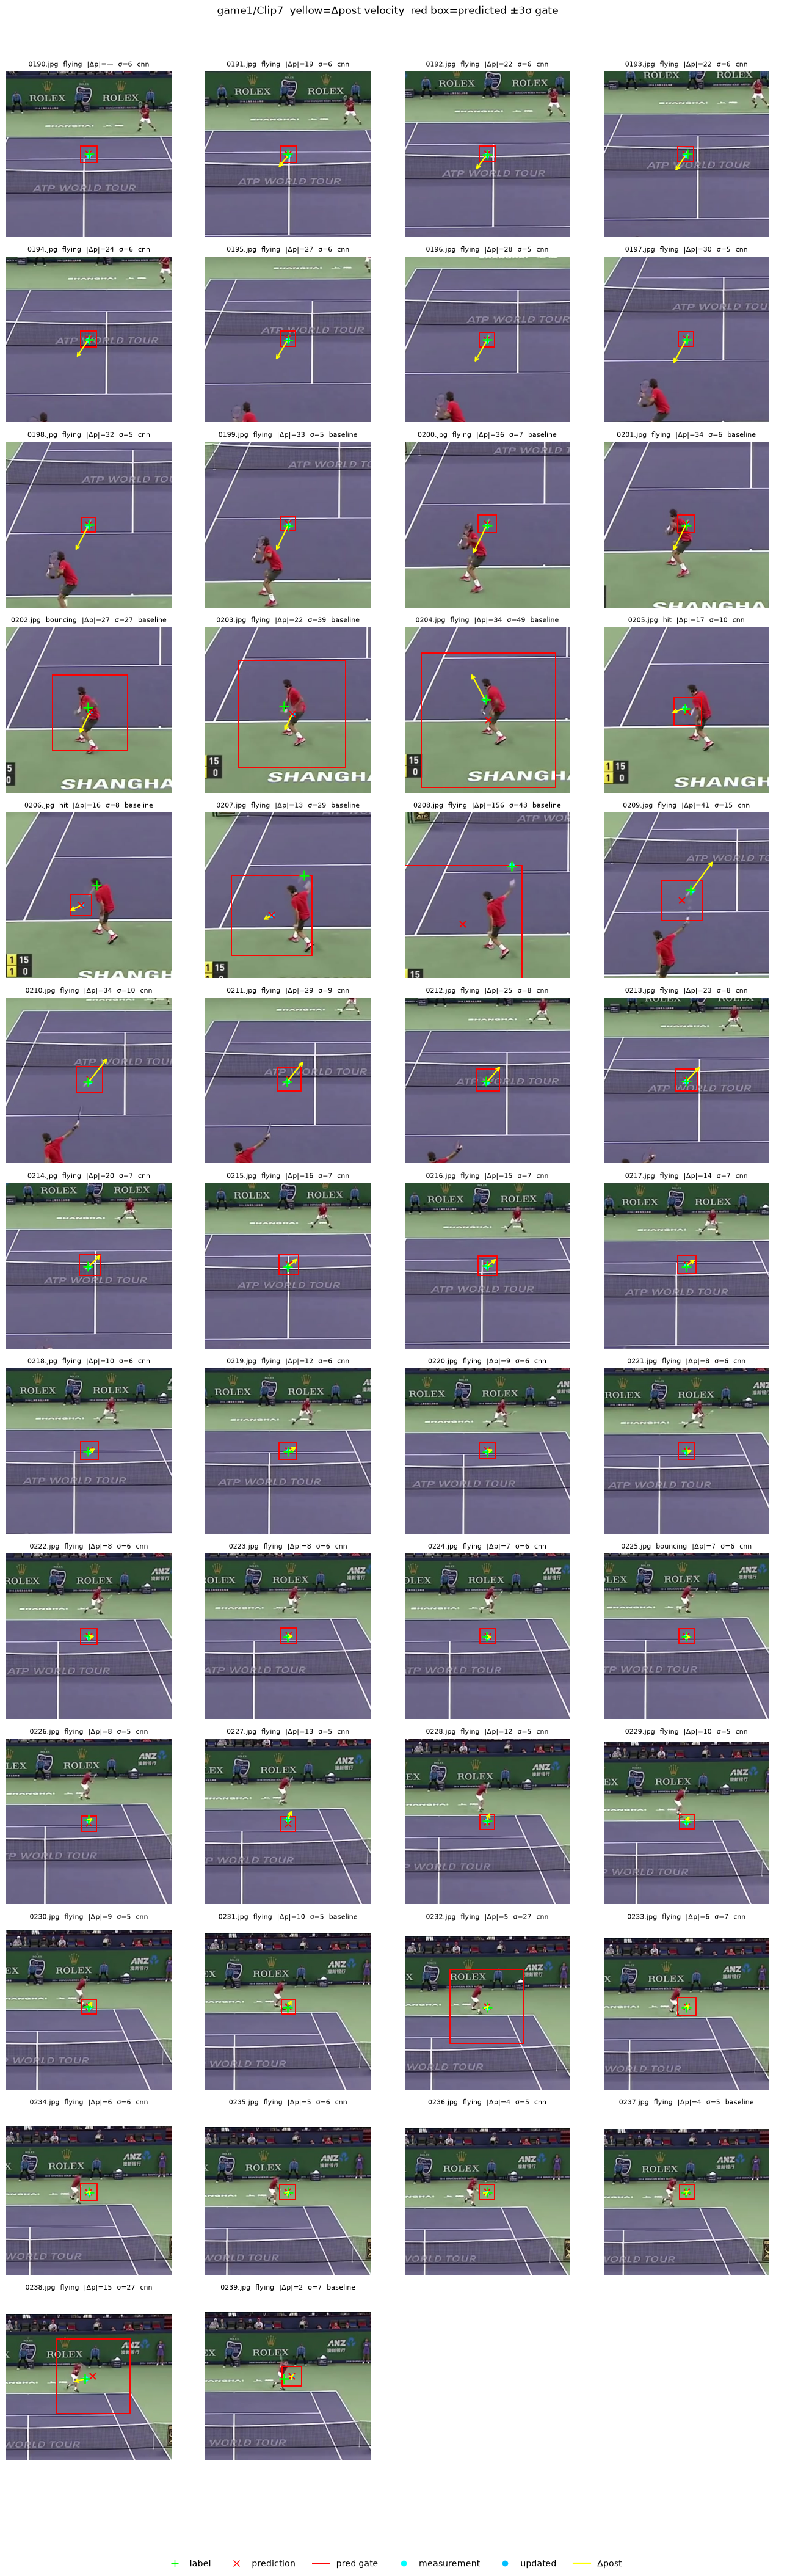

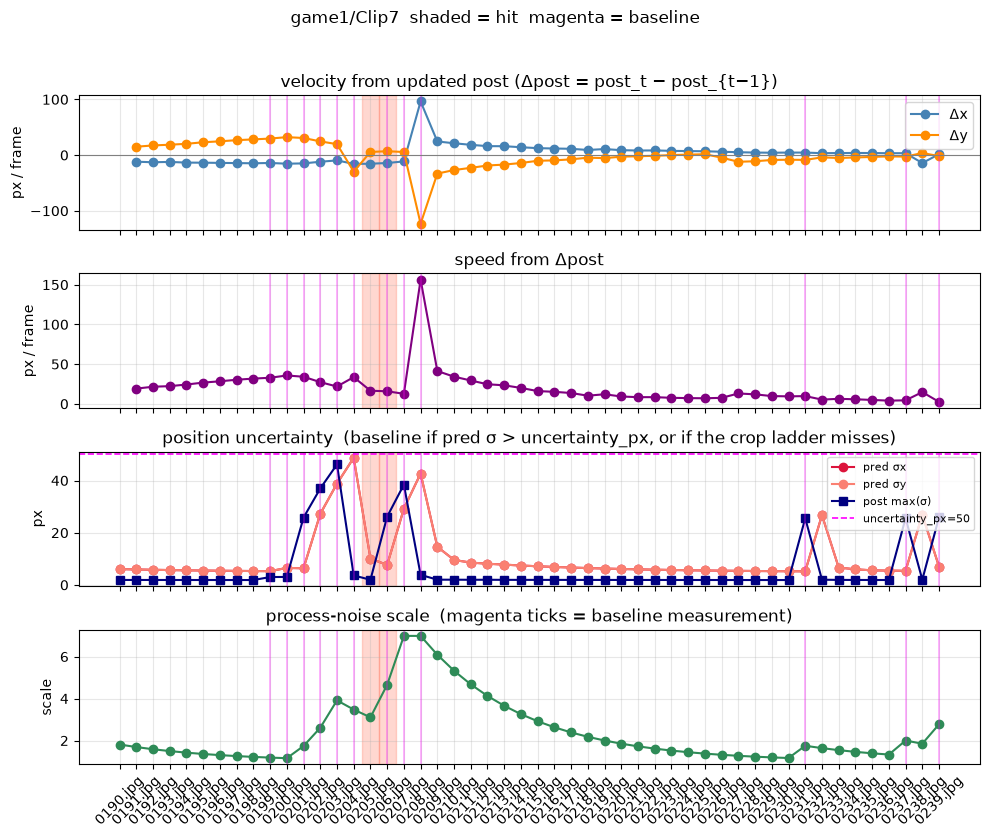

file        move      source         Δx       Δy     |Δp|   σpred   σpost   scale
0190.jpg    flying    cnn             —        —        —     6.1     1.9    1.81
0191.jpg    flying    cnn         -11.9     15.0     19.2     5.9     1.9    1.69
0192.jpg    flying    cnn         -12.9     17.3     21.6     5.8     1.9    1.59
0193.jpg    flying    cnn         -12.3     18.6     22.3     5.7     1.9    1.50
0194.jpg    flying    cnn         -13.5     20.2     24.3     5.6     1.9    1.42
0195.jpg    flying    cnn         -13.7     23.0     26.8     5.5     1.9    1.36
0196.jpg    flying    cnn         -14.0     24.7     28.4     5.4     1.9    1.31
0197.jpg    flying    cnn         -14.4     26.8     30.4     5.4     1.9    1.26
0198.jpg    flying    cnn         -14.7     28.2     31.8     5.3     1.9    1.22
0199.jpg    flying    baseline    -14.2     29.7     32.9     5.3     3.0    1.19
0200.jpg    flying    baseline    -15.5     32.2     35.7     6.5     3.1    1.16
0201.jpg    flyi

In [3]:
# AKF state over the same window: images with velocity + gate, then timelines.
# Velocity here is Δpost between consecutive updated positions (px/frame), not SSM vel.

ncols = 4
half = 180
nrows = int(np.ceil(COUNT / ncols))
# Arrow length in image pixels for a 1 px/frame velocity component.
VEL_SCALE = 2.0
UNCERT_LIM = tracker.rules.uncertainty_px

# Finite-difference velocity from updated post positions over the viewed window.
post_xy = [
    None if steps[i] is None else np.asarray(steps[i]["post"], dtype=np.float64)
    for i in window
]
vx = np.full(len(window), np.nan, dtype=np.float64)
vy = np.full(len(window), np.nan, dtype=np.float64)
for j in range(1, len(window)):
    if post_xy[j] is None or post_xy[j - 1] is None:
        continue
    vx[j] = post_xy[j][0] - post_xy[j - 1][0]
    vy[j] = post_xy[j][1] - post_xy[j - 1][1]
speed = np.hypot(vx, vy)

fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 3.3 * nrows))
for ax, j, i in zip(np.atleast_1d(axes).ravel(), range(len(window)), window):
    frame, step = clip[i], steps[i]
    bgr = cv2.imread(str(frame["path"]), cv2.IMREAD_COLOR)
    ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    if step is None:
        ax.set_title(f"{frame['file']}  no track", fontsize=9)
        ax.axis("off")
        continue

    x0, y0, x1, y1 = step["box"]
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", lw=1.4))
    ax.plot(*step["post"], "o", color="deepskyblue", ms=5)
    if step["pred"] is not None:
        ax.plot(*step["pred"], "x", color="red", ms=7, mew=1.4)
    if step["z"] is not None:
        ax.plot(*step["z"], "o", color="cyan", ms=5)
    xy = frame["xy"]
    if xy is not None:
        ax.plot(*xy, "+", color="lime", ms=11, mew=1.8)

    if np.isfinite(vx[j]) and np.isfinite(vy[j]):
        ax.annotate(
            "",
            xy=(step["post"][0] + VEL_SCALE * vx[j], step["post"][1] + VEL_SCALE * vy[j]),
            xytext=tuple(step["post"]),
            arrowprops=dict(arrowstyle="->", color="yellow", lw=1.6),
        )

    if xy is not None:
        center = xy if step["pred"] is None else 0.5 * (step["pred"] + xy)
    else:
        center = step["post"]
    ax.set_xlim(center[0] - half, center[0] + half)
    ax.set_ylim(center[1] + half, center[1] - half)

    speed_j = float(speed[j]) if np.isfinite(speed[j]) else float("nan")
    speed_txt = f"{speed_j:.0f}" if np.isfinite(speed_j) else "—"
    pred_u = float(np.max(step["pred_std"]))
    src = step.get("source") or "—"
    title = (
        f"{frame['file']}  {MOVEMENT[frame['status']]}  "
        f"|Δp|={speed_txt}  σ={pred_u:.0f}  {src}"
    )
    ax.set_title(title, fontsize=8)
    ax.axis("off")

for ax in np.atleast_1d(axes).ravel()[COUNT:]:
    ax.axis("off")

fig.legend(
    handles=[
        Line2D([0], [0], marker="+", color="lime", lw=0, ms=8, label="label"),
        Line2D([0], [0], marker="x", color="red", lw=0, ms=7, label="prediction"),
        Line2D([0], [0], color="red", lw=1.4, label="pred gate"),
        Line2D([0], [0], marker="o", color="cyan", lw=0, ms=6, label="measurement"),
        Line2D([0], [0], marker="o", color="deepskyblue", lw=0, ms=6, label="updated"),
        Line2D([0], [0], color="yellow", lw=1.6, label="Δpost"),
    ],
    loc="lower center",
    ncol=6,
    frameon=False,
)
fig.suptitle(
    f"{GAME}/{CLIP}  yellow=Δpost velocity  red box=predicted ±{tracker.gate_sigma:.0f}σ gate",
    fontsize=12,
)
fig.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.show()

names = [clip[i]["file"] for i in window]
scale = np.array([np.nan if steps[i] is None else steps[i]["scale"] for i in window])
pred_std_x = np.array([np.nan if steps[i] is None else steps[i]["pred_std"][0] for i in window])
pred_std_y = np.array([np.nan if steps[i] is None else steps[i]["pred_std"][1] for i in window])
pred_std_max = np.nanmax(np.stack([pred_std_x, pred_std_y]), axis=0)
pos_std_x = np.array([np.nan if steps[i] is None else steps[i]["pos_std"][0] for i in window])
pos_std_y = np.array([np.nan if steps[i] is None else steps[i]["pos_std"][1] for i in window])
pos_std_max = np.nanmax(np.stack([pos_std_x, pos_std_y]), axis=0)
status = np.array([clip[i]["status"] for i in window])
sources = [None if steps[i] is None else steps[i].get("source") for i in window]


def shade_hits(ax):
    for j, code in enumerate(status):
        if code != 1:
            continue
        ax.axvspan(j - 0.5, j + 0.5, color="tomato", alpha=0.25, zorder=0)


def mark_baseline(ax):
    for j, src in enumerate(sources):
        if src == "baseline":
            ax.axvline(j, color="magenta", alpha=0.35, lw=1.2)


fig, axes = plt.subplots(4, 1, figsize=(10.0, 8.5), sharex=True)

axes[0].plot(names, vx, marker="o", color="steelblue", label="Δx")
axes[0].plot(names, vy, marker="o", color="darkorange", label="Δy")
shade_hits(axes[0])
mark_baseline(axes[0])
axes[0].axhline(0.0, color="0.5", lw=0.8)
axes[0].set_ylabel("px / frame")
axes[0].set_title("velocity from updated post (Δpost = post_t − post_{t−1})")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

axes[1].plot(names, speed, marker="o", color="purple", label="|Δp|")
shade_hits(axes[1])
mark_baseline(axes[1])
axes[1].set_ylabel("px / frame")
axes[1].set_title("speed from Δpost")
axes[1].grid(True, alpha=0.3)

axes[2].plot(names, pred_std_x, marker="o", color="crimson", label="pred σx")
axes[2].plot(names, pred_std_y, marker="o", color="salmon", label="pred σy")
axes[2].plot(names, pos_std_max, marker="s", color="navy", label="post max(σ)")
shade_hits(axes[2])
mark_baseline(axes[2])
if UNCERT_LIM is not None:
    axes[2].axhline(
        UNCERT_LIM,
        color="magenta",
        ls="--",
        lw=1.2,
        label=f"uncertainty_px={UNCERT_LIM:g}",
    )
axes[2].set_ylabel("px")
axes[2].set_title(
    "position uncertainty  (baseline if pred σ > uncertainty_px, or if the crop ladder misses)"
)
axes[2].legend(loc="upper right", fontsize=8)
axes[2].grid(True, alpha=0.3)

axes[3].plot(names, scale, marker="o", color="seagreen", label="AKF scale")
shade_hits(axes[3])
mark_baseline(axes[3])
axes[3].set_ylabel("scale")
axes[3].set_title("process-noise scale  (magenta ticks = baseline measurement)")
axes[3].tick_params(axis="x", labelrotation=45)
axes[3].grid(True, alpha=0.3)

fig.suptitle(f"{GAME}/{CLIP}  shaded = hit  magenta = baseline", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

print(
    f"{'file':10}  {'move':8}  {'source':8}  {'Δx':>7}  {'Δy':>7}  {'|Δp|':>7}  "
    f"{'σpred':>6}  {'σpost':>6}  {'scale':>6}"
)
for j, i in enumerate(window):
    frame, step = clip[i], steps[i]
    if step is None:
        print(
            f"{frame['file']:10}  {MOVEMENT[frame['status']]:8}  {'—':8}  "
            f"{'—':>7}  {'—':>7}  {'—':>7}  {'—':>6}  {'—':>6}  {'—':>6}"
        )
        continue
    src = step.get("source") or "—"
    dx = f"{vx[j]:7.1f}" if np.isfinite(vx[j]) else "      —"
    dy = f"{vy[j]:7.1f}" if np.isfinite(vy[j]) else "      —"
    sp = f"{speed[j]:7.1f}" if np.isfinite(speed[j]) else "      —"
    print(
        f"{frame['file']:10}  {MOVEMENT[frame['status']]:8}  {src:8}  "
        f"{dx}  {dy}  {sp}  "
        f"{float(np.max(step['pred_std'])):6.1f}  {float(np.max(step['pos_std'])):6.1f}  "
        f"{step['scale']:6.2f}"
    )


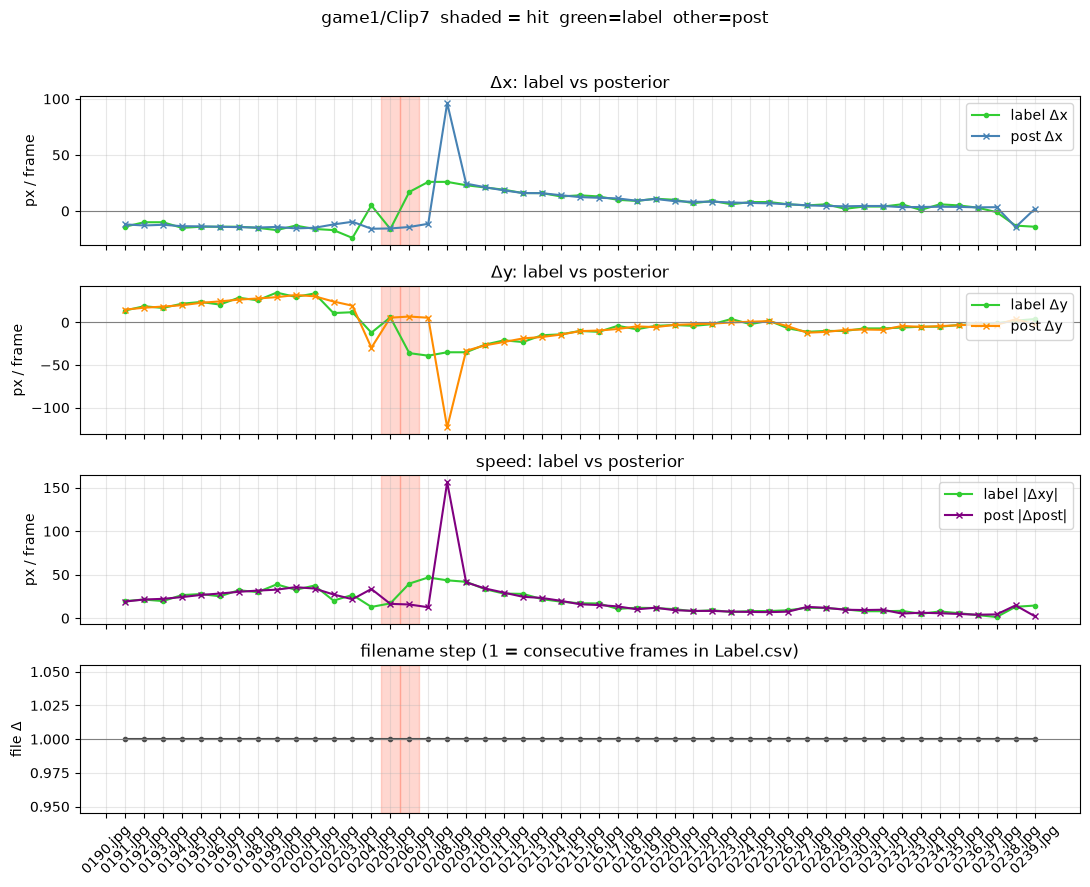

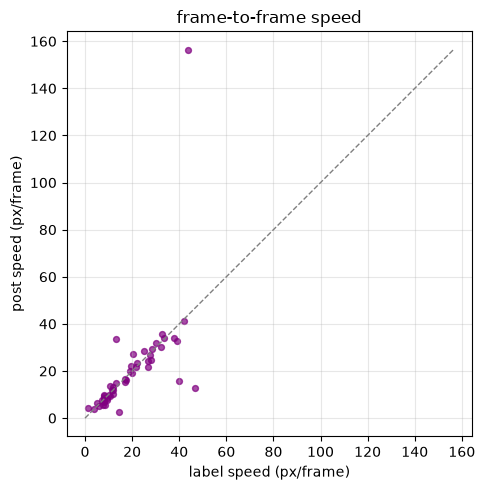

paired frames 49  mean post−label +1.2 px/frame  |err| mean 5.8  median 1.6  corr 0.612
non-unit filename steps in window: 0
flight    frames  label mean  label 1st  label 2nd  post mean  post 1st  post 2nd
0190.jpg->0205.jpg      15        25.9       24.7       27.0       27.1      24.7      29.2
0206.jpg->0239.jpg      33        15.2       22.5        8.4       17.2      27.2       7.7


In [4]:
# Posterior Δpost vs label Δxy on the same window.
# Both assume one clip step = one frame (30 fps). If label speed also rises mid-flight,
# that points at projection / camera geometry, not the filter inventing acceleration.

label_xy = [
    None if clip[i]["xy"] is None else np.asarray(clip[i]["xy"], dtype=np.float64)
    for i in window
]
post_xy = [
    None if steps[i] is None else np.asarray(steps[i]["post"], dtype=np.float64)
    for i in window
]

lvx = np.full(len(window), np.nan)
lvy = np.full(len(window), np.nan)
pvx = np.full(len(window), np.nan)
pvy = np.full(len(window), np.nan)
file_dt = np.full(len(window), np.nan)
for j in range(1, len(window)):
    i0, i1 = window[j - 1], window[j]
    file_dt[j] = int(Path(clip[i1]["file"]).stem) - int(Path(clip[i0]["file"]).stem)
    if label_xy[j] is not None and label_xy[j - 1] is not None:
        lvx[j] = label_xy[j][0] - label_xy[j - 1][0]
        lvy[j] = label_xy[j][1] - label_xy[j - 1][1]
    if post_xy[j] is not None and post_xy[j - 1] is not None:
        pvx[j] = post_xy[j][0] - post_xy[j - 1][0]
        pvy[j] = post_xy[j][1] - post_xy[j - 1][1]

lspeed = np.hypot(lvx, lvy)
pspeed = np.hypot(pvx, pvy)
names = [clip[i]["file"] for i in window]
status = np.array([clip[i]["status"] for i in window])


def shade_hits(ax):
    for j, code in enumerate(status):
        if code == 1:
            ax.axvspan(j - 0.5, j + 0.5, color="tomato", alpha=0.25, zorder=0)


fig, axes = plt.subplots(4, 1, figsize=(11.0, 9.0), sharex=True)

axes[0].plot(names, lvx, marker="o", ms=3, color="limegreen", label="label Δx")
axes[0].plot(names, pvx, marker="x", ms=4, color="steelblue", label="post Δx")
shade_hits(axes[0])
axes[0].axhline(0.0, color="0.5", lw=0.8)
axes[0].set_ylabel("px / frame")
axes[0].set_title("Δx: label vs posterior")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

axes[1].plot(names, lvy, marker="o", ms=3, color="limegreen", label="label Δy")
axes[1].plot(names, pvy, marker="x", ms=4, color="darkorange", label="post Δy")
shade_hits(axes[1])
axes[1].axhline(0.0, color="0.5", lw=0.8)
axes[1].set_ylabel("px / frame")
axes[1].set_title("Δy: label vs posterior")
axes[1].legend(loc="upper right")
axes[1].grid(True, alpha=0.3)

axes[2].plot(names, lspeed, marker="o", ms=3, color="limegreen", label="label |Δxy|")
axes[2].plot(names, pspeed, marker="x", ms=4, color="purple", label="post |Δpost|")
shade_hits(axes[2])
axes[2].set_ylabel("px / frame")
axes[2].set_title("speed: label vs posterior")
axes[2].legend(loc="upper right")
axes[2].grid(True, alpha=0.3)

axes[3].plot(names, file_dt, marker="o", ms=3, color="0.3")
shade_hits(axes[3])
axes[3].axhline(1.0, color="0.5", lw=0.8)
axes[3].set_ylabel("file Δ")
axes[3].set_title("filename step (1 = consecutive frames in Label.csv)")
axes[3].tick_params(axis="x", labelrotation=45)
axes[3].grid(True, alpha=0.3)

fig.suptitle(f"{GAME}/{CLIP}  shaded = hit  green=label  other=post", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

both = np.isfinite(lspeed) & np.isfinite(pspeed)
fig, ax = plt.subplots(figsize=(5.0, 5.0))
ax.scatter(lspeed[both], pspeed[both], c="purple", s=18, alpha=0.7)
lim = float(np.nanmax([lspeed[both].max(initial=0.0), pspeed[both].max(initial=0.0), 1.0]))
ax.plot([0, lim], [0, lim], color="0.5", ls="--", lw=1)
ax.set_xlabel("label speed (px/frame)")
ax.set_ylabel("post speed (px/frame)")
ax.set_title("frame-to-frame speed")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

if both.any():
    err = pspeed[both] - lspeed[both]
    corr = float(np.corrcoef(lspeed[both], pspeed[both])[0, 1])
    print(
        f"paired frames {both.sum()}  "
        f"mean post−label {err.mean():+.1f} px/frame  "
        f"|err| mean {np.abs(err).mean():.1f}  median {np.median(np.abs(err)):.1f}  "
        f"corr {corr:.3f}"
    )
else:
    print("no paired label/post speeds")

skips = int(np.sum(np.isfinite(file_dt) & (file_dt != 1)))
print(f"non-unit filename steps in window: {skips}")

# Flights between hits (and window edges). Compare early vs late label speed.
hit_js = [j for j, code in enumerate(status) if code == 1]
bounds = [0] + hit_js + [len(window) - 1]
print(
    f"{'flight':8}  {'frames':>6}  {'label mean':>10}  {'label 1st':>9}  "
    f"{'label 2nd':>9}  {'post mean':>9}  {'post 1st':>8}  {'post 2nd':>8}"
)
for k in range(len(bounds) - 1):
    a, b = bounds[k], bounds[k + 1]
    if b - a < 2:
        continue
    # Speeds live on the later frame of each step, so take (a+1)..b inclusive.
    sl = slice(a + 1, b + 1)
    lab = lspeed[sl]
    pst = pspeed[sl]
    lab_ok = lab[np.isfinite(lab)]
    pst_ok = pst[np.isfinite(pst)]
    if lab_ok.size < 2 and pst_ok.size < 2:
        continue
    mid = max(1, lab_ok.size // 2)
    mid_p = max(1, pst_ok.size // 2)
    lab_mean = f"{lab_ok.mean():10.1f}" if lab_ok.size else f"{'—':>10}"
    lab_1 = f"{lab_ok[:mid].mean():9.1f}" if lab_ok.size else f"{'—':>9}"
    lab_2 = f"{lab_ok[mid:].mean():9.1f}" if lab_ok.size > mid else f"{'—':>9}"
    pst_mean = f"{pst_ok.mean():9.1f}" if pst_ok.size else f"{'—':>9}"
    pst_1 = f"{pst_ok[:mid_p].mean():8.1f}" if pst_ok.size else f"{'—':>8}"
    pst_2 = f"{pst_ok[mid_p:].mean():8.1f}" if pst_ok.size > mid_p else f"{'—':>8}"
    start_file = names[a]
    end_file = names[b]
    print(
        f"{start_file}->{end_file[-8:]:8}  {b - a:6d}  "
        f"{lab_mean}  {lab_1}  {lab_2}  {pst_mean}  {pst_1}  {pst_2}"
    )


In [11]:
misses = weak = false = 0
errs, used, visibility, movement = [], [], [], []
spreads, rstds = [], []
for game in cfg["splits"]["test"]:
    game_dir = Path(cfg["paths"]["dataset"]) / game
    for clip_dir in sorted(p for p in game_dir.iterdir() if p.is_dir()):
        frames = load_clip(game, clip_dir.name)
        traced = run_clip(frames)
        for frame, step in zip(frames, traced):
            xy = frame["xy"]
            if step is None or step["post"] is None:
                if frame["visibility"] == 0:
                    misses += 1
                    if step is not None and step["z"] is not None:
                        false += 1
                continue
            if xy is None:
                misses += 1
                if step["z"] is not None:
                    false += 1
                continue
            errs.append(float(np.hypot(*(step["post"] - xy))))
            used.append(step["z"] is not None)
            visibility.append(frame["visibility"])
            movement.append(frame["status"])
            spreads.append(step["spread"])
            rstds.append(step["r_std"])
            if step["z"] is None:
                weak += 1

errs = np.asarray(errs)
used = np.asarray(used)
visibility = np.asarray(visibility)
movement = np.asarray(movement)
spreads = np.asarray(spreads, dtype=np.float64)
rstds = np.asarray(rstds, dtype=np.float64)


def _mean(values: np.ndarray) -> str:
    values = values[np.isfinite(values)]
    return f"{values.mean():5.1f}" if len(values) else "    —"


def show_group(name: str, mask: np.ndarray) -> None:
    count = int(mask.sum())
    if count == 0:
        return
    print(
        f"{name:16}  n={count:5d}  "
        f"dist={errs[mask].mean():6.1f}  "
        f"used={used[mask].mean():.3f}  "
        f"spread={_mean(spreads[mask])}  "
        f"r={_mean(rstds[mask & used])}"
    )


print(
    "test  dist = prediction error (px)  used = fraction where a crop found the ball  "
    "spread = heatmap sigma  r = measurement std on accepted frames"
)
show_group("all", np.ones(len(errs), dtype=bool))
print("movement")
for code, name in MOVEMENT.items():
    show_group(f"  {name}", movement == code)
print("obscurity")
print(f"{'  not in frame':16}  n={misses:5d}  false={false:5d}  accepted with no label")
print(f"{'  no detection':16}  n={weak:5d}  label present, no ball up to {MAX_SIDE}px")
for code, name in VISIBILITY.items():
    if code == 0:
        continue
    show_group(f"  {name}", visibility == code)


test  dist = prediction error (px)  used = fraction where a crop found the ball  spread = heatmap sigma  r = measurement std on accepted frames
all               n= 2044  dist=   6.6  used=0.903  spread=  2.0  r=  2.2
movement
  flying          n= 1940  dist=   6.1  used=0.914  spread=  2.0  r=  2.2
  hit             n=   48  dist=  23.8  used=0.396  spread=  2.2  r=  2.4
  bouncing        n=   56  dist=   8.6  used=0.946  spread=  1.9  r=  2.2
obscurity
  not in frame    n=   62  false=    0  accepted with no label
  no detection    n=  198  label present, no ball up to 720px
  visible         n= 1862  dist=   5.3  used=0.938  spread=  2.0  r=  2.2
  hard to see     n=  181  dist=  18.8  used=0.552  spread=  1.9  r=  2.2
  occluded        n=    1  dist= 100.3  used=0.000  spread=    —  r=    —


In [ ]:





#Post 
test  dist = prediction error (px)  used = fraction where a crop found the ball  spread = heatmap sigma  r = measurement std on accepted frames
all               n= 2058  dist=  10.0  used=0.973  spread=  3.5  r=  3.2
movement
  flying          n= 1953  dist=   9.2  used=0.977  spread=  3.4  r=  3.2
  hit             n=   48  dist=  34.0  used=0.792  spread= 10.8  r=  8.7
  bouncing        n=   57  dist=  15.3  used=0.965  spread=  1.7  r=  2.0
obscurity
  not in frame    n=   62  false=   17  accepted with no label
  no detection    n=   56  label present, no ball up to 720px
  visible         n= 1875  dist=   8.9  used=0.986  spread=  3.4  r=  3.2
  hard to see     n=  182  dist=  21.6  used=0.841  spread=  4.5  r=  3.8
  occluded        n=    1  dist=   1.0  used=0.000  spread=    —  r=    —

# Base AKF
test  dist = prediction error (px)  used = fraction where a crop found the ball  spread = heatmap sigma  r = measurement std on accepted frames
all               n= 2046  dist=  13.5  used=0.973  spread=  3.1  r=  3.1
movement
  flying          n= 1942  dist=  12.6  used=0.977  spread=  3.0  r=  3.0
  hit             n=   48  dist=  35.6  used=0.792  spread= 10.8  r=  8.7
  bouncing        n=   56  dist=  26.0  used=0.964  spread=  1.7  r=  2.0
obscurity
  not in frame    n=   62  false=   17  accepted with no label
  no detection    n=   56  label present, no ball up to 720px
  visible         n= 1863  dist=  12.5  used=0.986  spread=  2.9  r=  3.0
  hard to see     n=  182  dist=  24.0  used=0.841  spread=  4.5  r=  3.8
  occluded        n=    1  dist=   1.0  used=0.000  spread=    —  r=    —
